## Extracao dos dados

In [2]:
import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, roc_curve, roc_auc_score
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)

SEED = 42
np.random.seed(SEED)

# procura a raiz do projeto para nao depender de caminho fixo
raiz_do_projeto = Path.cwd().resolve()
while not (raiz_do_projeto / "pyproject.toml").exists():
    if raiz_do_projeto.parent == raiz_do_projeto:
        raise FileNotFoundError("Nao encontrei o pyproject.toml. Abra o notebook dentro do repositorio.")
    raiz_do_projeto = raiz_do_projeto.parent

dataframe_de_churn_inicial = pd.read_csv(raiz_do_projeto / "data" / "raw" / "Telco-Customer-Churn.csv", sep=",")
dataframe_de_churn_inicial.shape

(7043, 21)

## Tratamento dos dados (mesmo do V10)

In [3]:
colunas_pt_br = {
    "customerID": "id_cliente",
    "gender": "genero",
    "SeniorCitizen": "cliente_em_idade_avancada",
    "Partner": "casado",
    "Dependents": "dependentes",
    "tenure": "meses_como_cliente",
    "PhoneService": "possui_servico_telefonico",
    "MultipleLines": "possui_multiplas_linhas",
    "InternetService": "possui_servico_de_internet",
    "OnlineSecurity": "possui_seguranca_online",
    "OnlineBackup": "possui_backup_online",
    "DeviceProtection": "possui_protecao_dispositivo",
    "TechSupport": "possui_suporte_tecnico_premium",
    "StreamingTV": "possui_streaming_tv_terceiros",
    "StreamingMovies": "possui_streaming_filmes_terceiros",
    "Contract": "tipo_contrato",
    "PaperlessBilling": "fatura_sem_papel",
    "PaymentMethod": "metodo_pagamento",
    "MonthlyCharges": "cobranca_mensal",
    "TotalCharges": "total_cobrado_durante_trimestre",
    "Churn": "target",
}

df = dataframe_de_churn_inicial.rename(columns=colunas_pt_br)
df["target"] = df["target"].map({"Yes": 1, "No": 0})

# removendo identificador e features sensiveis
df = df.drop(columns=["id_cliente", "genero", "dependentes"])

# binarizando features deterministicas
for coluna in ["casado", "fatura_sem_papel", "possui_servico_telefonico"]:
    df[coluna] = df[coluna].map({"Yes": 1, "No": 0})

# binarias nao deterministicas
colunas_addons = [
    "possui_seguranca_online",
    "possui_backup_online",
    "possui_protecao_dispositivo",
    "possui_suporte_tecnico_premium",
    "possui_streaming_tv_terceiros",
    "possui_streaming_filmes_terceiros",
]
for coluna in colunas_addons:
    df[coluna] = df[coluna].map({"Yes": 1, "No": 0, "No internet service": 0})
df["possui_multiplas_linhas"] = df["possui_multiplas_linhas"].map({"Yes": 1, "No": 0, "No phone service": 0})
df["tipo_contrato"] = df["tipo_contrato"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})

# one hot
servico_de_internet_dummies = pd.get_dummies(
    df["possui_servico_de_internet"].map({"No": "sem_internet", "Fiber optic": "fibra_optica", "DSL": "dsl"}),
    prefix="possui_servico_de_internet",
).astype(int)
metodo_pagamento_dummies = pd.get_dummies(
    df["metodo_pagamento"].map({
        "Mailed check": "mailed_check",
        "Electronic check": "electronic_check",
        "Bank transfer (automatic)": "bank_transfer_automatic",
        "Credit card (automatic)": "credit_card_automatic",
    }),
    prefix="metodo_pagamento",
).astype(int)
df = pd.concat(
    [df.drop(columns=["possui_servico_de_internet", "metodo_pagamento"]), servico_de_internet_dummies, metodo_pagamento_dummies],
    axis=1,
)

# removendo clientes com 0 meses e cobranca vazia
total_cobrado_numerico = pd.to_numeric(df["total_cobrado_durante_trimestre"], errors="coerce")
sem_historico = (df["meses_como_cliente"] == 0) & (total_cobrado_numerico.isna() | (total_cobrado_numerico == 0))
df = df[~sem_historico].copy()

# addons e remocao do total cobrado (colinearidade)
df["quantidade_de_addons"] = df[colunas_addons].sum(axis=1)
df = df.drop(columns=["total_cobrado_durante_trimestre"])

# duplicatas
df = df.drop_duplicates()

print(f"Registros finais: {df.shape[0]} | Colunas: {df.shape[1]}")
print(df["target"].value_counts(normalize=True).round(4))

Registros finais: 6959 | Colunas: 23
target
0    0.7353
1    0.2647
Name: proportion, dtype: float64


## Dividindo dados entre treino e teste

In [4]:
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")

X_train: (4871, 22), X_test: (2088, 22)


## Pipeline com escalonamento, SMOTE e MLPClassifier

In [5]:
colunas_para_escalonar = ["meses_como_cliente", "tipo_contrato", "cobranca_mensal", "quantidade_de_addons"]

escalonador = ColumnTransformer(
    [("escala", StandardScaler(), colunas_para_escalonar)],
    remainder="passthrough",
    verbose_feature_names_out=False,
)

def criar_pipeline_mlp(**parametros_mlp):
    mlp = MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        solver="adam",
        alpha=1e-3,
        learning_rate_init=1e-3,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=SEED,
    )
    mlp.set_params(**parametros_mlp)
    return Pipeline([
        ("escala", escalonador),
        ("smote", SMOTE(random_state=SEED)),
        ("mlp", mlp),
    ])

modelo_mlp = criar_pipeline_mlp()
modelo_mlp

Pipeline(steps=[('escala',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('escala', StandardScaler(),
                                                  ['meses_como_cliente',
                                                   'tipo_contrato',
                                                   'cobranca_mensal',
                                                   'quantidade_de_addons'])],
                                   verbose_feature_names_out=False)),
                ('smote', SMOTE(random_state=42)),
                ('mlp',
                 MLPClassifier(alpha=0.001, early_stopping=True,
                               hidden_layer_sizes=(32, 16), max_iter=500,
                               n_iter_no_change=20, random_state=42))])

## Validacao cruzada estratificada (K-Fold) da rede inicial

In [6]:
k_fold_estratificado = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
metricas_cv = {"acuracia": "accuracy", "precisao": "precision", "recall": "recall", "f1_score": "f1", "roc_auc": "roc_auc"}

resultado_cv = cross_validate(modelo_mlp, X_train, y_train, cv=k_fold_estratificado, scoring=metricas_cv)

tabela_metricas_cv = pd.DataFrame({nome: resultado_cv[f"test_{nome}"] for nome in metricas_cv})
tabela_metricas_cv.insert(0, "fold", range(1, 6))
print(tabela_metricas_cv.round(4).to_string(index=False))
print("\nMedia +/- desvio padrao entre os 5 folds:")
for nome in metricas_cv:
    print(f"{nome}: {tabela_metricas_cv[nome].mean():.4f} +/- {tabela_metricas_cv[nome].std():.4f}")

 fold  acuracia  precisao  recall  f1_score  roc_auc
    1    0.7703    0.5475  0.7597    0.6364   0.8448
    2    0.7649    0.5383  0.7665    0.6324   0.8457
    3    0.7659    0.5408  0.7713    0.6358   0.8418
    4    0.7485    0.5160  0.8101    0.6305   0.8401
    5    0.7485    0.5186  0.7016    0.5964   0.8221

Media +/- desvio padrao entre os 5 folds:
acuracia: 0.7596 +/- 0.0104
precisao: 0.5322 +/- 0.0140
recall: 0.7618 +/- 0.0390
f1_score: 0.6263 +/- 0.0169
roc_auc: 0.8389 +/- 0.0097


## Busca de hiperparametros com GridSearch

In [7]:
grade_de_parametros = {
    "mlp__hidden_layer_sizes": [(16,), (32,), (32, 16), (64, 32)],
    "mlp__alpha": [1e-4, 1e-3, 1e-2],
    "mlp__learning_rate_init": [1e-3, 1e-2],
}

busca = GridSearchCV(
    criar_pipeline_mlp(),
    grade_de_parametros,
    cv=k_fold_estratificado,
    scoring="roc_auc",
    n_jobs=-1,
)
busca.fit(X_train, y_train)

print("Melhores parametros:", busca.best_params_)
print(f"AUC-ROC media na validacao cruzada: {busca.best_score_:.4f}")

ranking = pd.DataFrame(busca.cv_results_)[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
ranking.sort_values("rank_test_score").head(8)

Melhores parametros: {'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (32,), 'mlp__learning_rate_init': 0.001}
AUC-ROC media na validacao cruzada: 0.8436


,params,mean_test_score,std_test_score,rank_test_score
18,"{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes'...",0.843644,0.009901,1
10,"{'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes...",0.841959,0.011147,2
8,"{'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes...",0.841946,0.012817,3
16,"{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes'...",0.841825,0.012752,4
0,"{'mlp__alpha': 0.0001, 'mlp__hidden_layer_size...",0.841227,0.013081,5
2,"{'mlp__alpha': 0.0001, 'mlp__hidden_layer_size...",0.840905,0.012164,6
20,"{'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes'...",0.840012,0.012934,7
12,"{'mlp__alpha': 0.001, 'mlp__hidden_layer_sizes...",0.838921,0.008638,8


## Validacao cruzada da melhor rede

In [8]:
melhor_mlp = busca.best_estimator_

resultado_cv_melhor = cross_validate(melhor_mlp, X_train, y_train, cv=k_fold_estratificado, scoring=metricas_cv)
cv_melhor = {nome: (resultado_cv_melhor[f"test_{nome}"].mean(), resultado_cv_melhor[f"test_{nome}"].std()) for nome in metricas_cv}
for nome, (media, desvio) in cv_melhor.items():
    print(f"{nome}: {media:.4f} +/- {desvio:.4f}")

acuracia: 0.7543 +/- 0.0086
precisao: 0.5245 +/- 0.0117
recall: 0.7766 +/- 0.0392
f1_score: 0.6256 +/- 0.0137
roc_auc: 0.8436 +/- 0.0099


## Curva de aprendizado

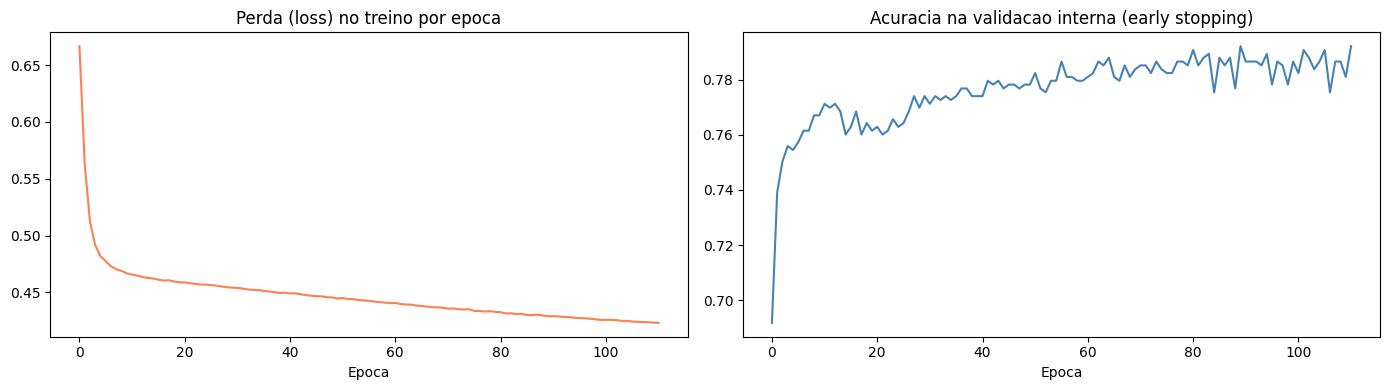

Epocas treinadas: 111


In [9]:
rede_treinada = melhor_mlp.named_steps["mlp"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(rede_treinada.loss_curve_, color="coral")
axes[0].set_title("Perda (loss) no treino por epoca")
axes[0].set_xlabel("Epoca")
axes[1].plot(rede_treinada.validation_scores_, color="steelblue")
axes[1].set_title("Acuracia na validacao interna (early stopping)")
axes[1].set_xlabel("Epoca")
plt.tight_layout()
plt.show()

print(f"Epocas treinadas: {rede_treinada.n_iter_}")

## Escolha do limiar pelo custo de negocio
Custo = FN x (cobranca_mensal x meses perdidos) + FP x custo do contato. Premissas provisorias.

Limiar de menor custo (validacao cruzada no treino): 0.15


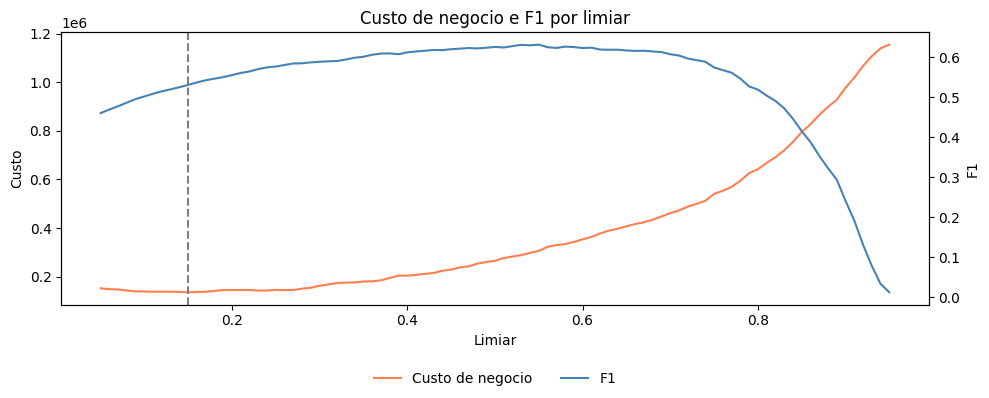

In [14]:
MESES_DE_RECEITA_PERDIDA = 12   # premissa provisoria
CUSTO_DE_UM_CONTATO = 50.0      # premissa provisoria

def custo_de_negocio(y_real, y_previsto, cobranca_mensal):
    y_real, y_previsto, cobranca_mensal = np.asarray(y_real), np.asarray(y_previsto), np.asarray(cobranca_mensal)
    falsos_negativos = (y_real == 1) & (y_previsto == 0)
    falsos_positivos = (y_real == 0) & (y_previsto == 1)
    custo_fn = (cobranca_mensal[falsos_negativos] * MESES_DE_RECEITA_PERDIDA).sum()
    custo_fp = falsos_positivos.sum() * CUSTO_DE_UM_CONTATO
    return custo_fn + custo_fp

proba_cv_treino = cross_val_predict(melhor_mlp, X_train, y_train, cv=k_fold_estratificado, method="predict_proba")[:, 1]

limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
tabela_limiares = pd.DataFrame({
    "limiar": limiares,
    "custo": [custo_de_negocio(y_train, (proba_cv_treino >= t).astype(int), X_train["cobranca_mensal"]) for t in limiares],
    "f1_score": [f1_score(y_train, (proba_cv_treino >= t).astype(int)) for t in limiares],
})
limiar_escolhido = float(tabela_limiares.loc[tabela_limiares["custo"].idxmin(), "limiar"])
print(f"Limiar de menor custo (validacao cruzada no treino): {limiar_escolhido:.2f}")

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(tabela_limiares["limiar"], tabela_limiares["custo"], color="coral", label="Custo de negocio")
ax1.axvline(limiar_escolhido, linestyle="--", color="gray")
ax1.set_xlabel("Limiar")
ax1.set_ylabel("Custo")
ax2 = ax1.twinx()
ax2.plot(tabela_limiares["limiar"], tabela_limiares["f1_score"], color="steelblue", label="F1")
ax2.set_ylabel("F1")
fig.legend(loc="lower center", ncol=2, frameon=False)
plt.title("Custo de negocio e F1 por limiar")
plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## Avaliacao no teste

 limiar  acuracia  precisao  recall  f1_score  roc_auc  custo_de_negocio
   0.50    0.7452    0.5126  0.7722    0.6162   0.8297          123548.6
   0.15    0.5824    0.3830  0.9439    0.5449   0.8297           67294.4


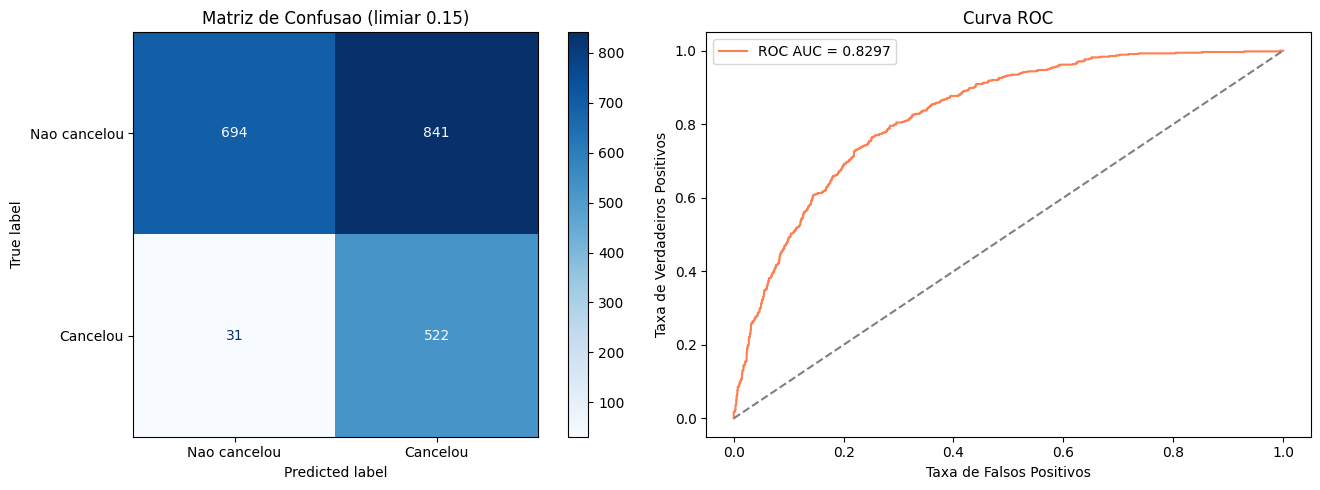

In [11]:
y_proba = melhor_mlp.predict_proba(X_test)[:, 1]

def metricas_no_teste(limiar):
    y_pred = (y_proba >= limiar).astype(int)
    return {
        "limiar": limiar,
        "acuracia": accuracy_score(y_test, y_pred),
        "precisao": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1_score": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "custo_de_negocio": custo_de_negocio(y_test, y_pred, X_test["cobranca_mensal"]),
    }

# limiar 0.5 (igual ao V10) e limiar de menor custo
resultado_teste = pd.DataFrame([metricas_no_teste(0.5), metricas_no_teste(limiar_escolhido)])
print(resultado_teste.round(4).to_string(index=False))

y_pred = (y_proba >= limiar_escolhido).astype(int)
matriz_confusao = confusion_matrix(y_test, y_pred)
fpr, tpr, _ = roc_curve(y_test, y_proba)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix=matriz_confusao, display_labels=["Nao cancelou", "Cancelou"]).plot(ax=axes[0], cmap="Blues")
axes[0].set_title(f"Matriz de Confusao (limiar {limiar_escolhido:.2f})")
axes[1].plot(fpr, tpr, color="coral", label=f"ROC AUC = {roc_auc_score(y_test, y_proba):.4f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[1].set_xlabel("Taxa de Falsos Positivos")
axes[1].set_ylabel("Taxa de Verdadeiros Positivos")
axes[1].set_title("Curva ROC")
axes[1].legend()
plt.tight_layout()
plt.show()

## Comparacao com a Regressao Logistica (V10)

In [12]:
baseline_v10_teste = {"modelo": "Regressao Logistica (V10)", "limiar": 0.5, "acuracia": 0.7725, "precisao": 0.5557,
                      "recall": 0.7034, "f1_score": 0.6209, "roc_auc": 0.8308}

mlp_teste_05 = {"modelo": "MLPClassifier (V1)", **metricas_no_teste(0.5)}
mlp_teste_custo = {"modelo": "MLPClassifier (V1) - limiar de custo", **metricas_no_teste(limiar_escolhido)}

tabela_comparativa = pd.DataFrame([baseline_v10_teste, mlp_teste_05, mlp_teste_custo])
tabela_comparativa.round(4)

,modelo,limiar,acuracia,precisao,recall,f1_score,roc_auc,custo_de_negocio
0,Regressao Logistica (V10),0.50,0.7725,0.5557,0.7034,0.6209,0.8308,NaN
1,MLPClassifier (V1),0.50,0.7452,0.5126,0.7722,0.6162,0.8297,123548.6
2,MLPClassifier (V1) - limiar de custo,0.15,0.5824,0.3830,0.9439,0.5449,0.8297,67294.4


## Registro de metricas e salvamento do modelo

In [13]:
pasta_do_notebook = raiz_do_projeto / "notebooks" / "redes_neurais" / "historico"
metricas_dir = pasta_do_notebook / "metrics"
metricas_dir.mkdir(parents=True, exist_ok=True)

metricas = {
    "melhores_parametros": {k: (list(v) if isinstance(v, tuple) else v) for k, v in busca.best_params_.items()},
    "cv_treino": {nome: {"media": media, "desvio": desvio} for nome, (media, desvio) in cv_melhor.items()},
    "teste_limiar_0_5": metricas_no_teste(0.5),
    "teste_limiar_custo": metricas_no_teste(limiar_escolhido),
    "premissas_custo": {"meses_de_receita_perdida": MESES_DE_RECEITA_PERDIDA, "custo_de_um_contato": CUSTO_DE_UM_CONTATO},
    "matriz_confusao_limiar_custo": matriz_confusao.tolist(),
}
with open(metricas_dir / "metrics.json", "w") as arquivo_metricas:
    json.dump(metricas, arquivo_metricas, indent=4, default=float)

pasta_modelos = raiz_do_projeto / "models" / "v1.0.0"
pasta_modelos.mkdir(parents=True, exist_ok=True)
joblib.dump(
    {"pipeline": melhor_mlp, "limiar": limiar_escolhido, "colunas": X.columns.tolist()},
    pasta_modelos / "mlp_classifier.joblib",
)
print("Metricas salvas em:", metricas_dir / "metrics.json")
print("Modelo salvo em:", pasta_modelos / "mlp_classifier.joblib")

Metricas salvas em: /content/Tech_Challenge_Churn_Prediction-main/notebooks/redes_neurais/historico/metrics/metrics.json
Modelo salvo em: /content/Tech_Challenge_Churn_Prediction-main/models/v1.0.0/mlp_classifier.joblib
